In [1]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
from numpy.random.mtrand import logistic
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score, TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Prevendo

## Ajustando a os dados

In [2]:
dados = pd.read_csv('hist_moeda_rows.csv')
df = pd.DataFrame(dados)
df.head()

,Simbolo,Data,Open,High,Low,Close
0,ITUB4,21/10/2024,31.2357,31.2621,30.8914,30.9797
1,ITUB4,22/10/2024,30.8914,31.1121,30.7237,31.0327
2,ITUB4,23/10/2024,30.9003,31.2445,30.8914,31.2268
3,ITUB4,24/10/2024,31.2268,31.6240,31.1474,31.5093
4,ITUB4,25/10/2024,31.5093,31.5799,31.0856,31.1562


In [3]:
#Transformando os Simbolos em números para facilitar o nosso modelo
encoder = LabelEncoder()
df['Simbolo'] = encoder.fit_transform(df['Simbolo'])
df['Data'] = pd.to_datetime(df['Data'],format='%d/%m/%Y')
df = df.sort_values(['Simbolo','Data']).reset_index(drop=True)
df.head()

,Simbolo,Data,Open,High,Low,Close
0,0,2024-10-21,31.2357,31.2621,30.8914,30.9797
1,0,2024-10-22,30.8914,31.1121,30.7237,31.0327
2,0,2024-10-23,30.9003,31.2445,30.8914,31.2268
3,0,2024-10-24,31.2268,31.6240,31.1474,31.5093
4,0,2024-10-25,31.5093,31.5799,31.0856,31.1562


In [4]:
#Retornos de cada dia
df['ret_Close'] = df['Close'].pct_change() #Rentabilidade do Close de um dia para o outro
df['ret_Open'] = df['Open'].pct_change() #Rentabilidade do Open de um dia para o outro
df.head()

,Simbolo,Data,Open,High,Low,Close,ret_Close,ret_Open
0,0,2024-10-21,31.2357,31.2621,30.8914,30.9797,NaN,NaN
1,0,2024-10-22,30.8914,31.1121,30.7237,31.0327,0.001711,-0.011023
2,0,2024-10-23,30.9003,31.2445,30.8914,31.2268,0.006255,0.000288
3,0,2024-10-24,31.2268,31.6240,31.1474,31.5093,0.009047,0.010566
4,0,2024-10-25,31.5093,31.5799,31.0856,31.1562,-0.011206,0.009047


In [5]:
#Defasagens do dia anteriror
for i in [1,2,3,4,5]:
    df[f"ret_lag_{i}"] = df["ret_Close"].shift(i)

df.head(10)

,Simbolo,Data,Open,High,Low,Close,ret_Close,ret_Open,ret_lag_1,ret_lag_2,ret_lag_3,ret_lag_4,ret_lag_5
0,0,2024-10-21,31.2357,31.2621,30.8914,30.9797,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,2024-10-22,30.8914,31.1121,30.7237,31.0327,0.001711,-0.011023,NaN,NaN,NaN,NaN,NaN
2,0,2024-10-23,30.9003,31.2445,30.8914,31.2268,0.006255,0.000288,0.001711,NaN,NaN,NaN,NaN
3,0,2024-10-24,31.2268,31.6240,31.1474,31.5093,0.009047,0.010566,0.006255,0.001711,NaN,NaN,NaN
4,0,2024-10-25,31.5093,31.5799,31.0856,31.1562,-0.011206,0.009047,0.009047,0.006255,0.001711,NaN,NaN
5,0,2024-10-28,31.4563,31.6946,31.3239,31.5357,0.012181,-0.001682,-0.011206,0.009047,0.006255,0.001711,NaN
6,0,2024-10-29,31.6505,31.7211,31.2004,31.2004,-0.010632,0.006174,0.012181,-0.011206,0.009047,0.006255,0.001711
7,0,2024-10-30,31.1915,31.4122,31.0062,31.1121,-0.002830,-0.014502,-0.010632,0.012181,-0.011206,0.009047,0.006255
8,0,2024-10-31,31.1121,31.4298,30.9091,30.9091,-0.006525,-0.002546,-0.002830,-0.010632,0.012181,-0.011206,0.009047
9,0,2024-11-01,30.8914,31.1562,30.7061,30.7237,-0.005998,-0.007094,-0.006525,-0.002830,-0.010632,0.012181,-0.011206


In [6]:
# Métricas
df['sma_5'] = df['Close'].rolling(5).mean() #Média a curto prazo, com o período de 5 dias
df['sma_20'] = df['Close'].rolling(20).mean() #Média a longo prazo, com o período de 20 dias
df['vol_20'] = df['Close'].rolling(20).std()  #
df["range"] = (df["High"] - df["Low"])/df['Close'] #Variação que a ação tem no dia
df.head()

,Simbolo,Data,Open,High,Low,Close,ret_Close,ret_Open,ret_lag_1,ret_lag_2,ret_lag_3,ret_lag_4,ret_lag_5,sma_5,sma_20,vol_20,range
0,0,2024-10-21,31.2357,31.2621,30.8914,30.9797,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.011966
1,0,2024-10-22,30.8914,31.1121,30.7237,31.0327,0.001711,-0.011023,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.012516
2,0,2024-10-23,30.9003,31.2445,30.8914,31.2268,0.006255,0.000288,0.001711,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.011308
3,0,2024-10-24,31.2268,31.6240,31.1474,31.5093,0.009047,0.010566,0.006255,0.001711,NaN,NaN,NaN,NaN,NaN,NaN,0.015126
4,0,2024-10-25,31.5093,31.5799,31.0856,31.1562,-0.011206,0.009047,0.009047,0.006255,0.001711,NaN,NaN,31.18094,NaN,NaN,0.015865


In [7]:
# Colunas de Datas
df['Month'] = df['Data'].dt.month
df['Day'] = df['Data'].dt.day
df['Year'] = df['Data'].dt.year
df['DayOfWeek'] = df['Data'].dt.day_of_week
df.head(10)

,Simbolo,Data,Open,High,Low,Close,ret_Close,ret_Open,ret_lag_1,ret_lag_2,...,ret_lag_4,ret_lag_5,sma_5,sma_20,vol_20,range,Month,Day,Year,DayOfWeek
0,0,2024-10-21,31.2357,31.2621,30.8914,30.9797,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.011966,10,21,2024,0
1,0,2024-10-22,30.8914,31.1121,30.7237,31.0327,0.001711,-0.011023,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.012516,10,22,2024,1
2,0,2024-10-23,30.9003,31.2445,30.8914,31.2268,0.006255,0.000288,0.001711,NaN,...,NaN,NaN,NaN,NaN,NaN,0.011308,10,23,2024,2
3,0,2024-10-24,31.2268,31.6240,31.1474,31.5093,0.009047,0.010566,0.006255,0.001711,...,NaN,NaN,NaN,NaN,NaN,0.015126,10,24,2024,3
4,0,2024-10-25,31.5093,31.5799,31.0856,31.1562,-0.011206,0.009047,0.009047,0.006255,...,NaN,NaN,31.18094,NaN,NaN,0.015865,10,25,2024,4
5,0,2024-10-28,31.4563,31.6946,31.3239,31.5357,0.012181,-0.001682,-0.011206,0.009047,...,0.001711,NaN,31.29214,NaN,NaN,0.011755,10,28,2024,0
6,0,2024-10-29,31.6505,31.7211,31.2004,31.2004,-0.010632,0.006174,0.012181,-0.011206,...,0.006255,0.001711,31.32568,NaN,NaN,0.016689,10,29,2024,1
7,0,2024-10-30,31.1915,31.4122,31.0062,31.1121,-0.002830,-0.014502,-0.010632,0.012181,...,0.009047,0.006255,31.30274,NaN,NaN,0.013050,10,30,2024,2
8,0,2024-10-31,31.1121,31.4298,30.9091,30.9091,-0.006525,-0.002546,-0.002830,-0.010632,...,-0.011206,0.009047,31.18270,NaN,NaN,0.016846,10,31,2024,3
9,0,2024-11-01,30.8914,31.1562,30.7061,30.7237,-0.005998,-0.007094,-0.006525,-0.002830,...,0.012181,-0.011206,31.09620,NaN,NaN,0.014650,11,1,2024,4


In [8]:
#Coluna "Amanhã", y para o nosso modelo
df['open_Tomorrow'] = df['Open'].shift(-1)
df['high_Tomorrow'] = df['High'].shift(-1)
df['low_Tomorrow'] = df['Low'].shift(-1)
df['close_Tomorrow'] = df['Close'].shift(-1)
df.head(10)

,Simbolo,Data,Open,High,Low,Close,ret_Close,ret_Open,ret_lag_1,ret_lag_2,...,vol_20,range,Month,Day,Year,DayOfWeek,open_Tomorrow,high_Tomorrow,low_Tomorrow,close_Tomorrow
0,0,2024-10-21,31.2357,31.2621,30.8914,30.9797,NaN,NaN,NaN,NaN,...,NaN,0.011966,10,21,2024,0,30.8914,31.1121,30.7237,31.0327
1,0,2024-10-22,30.8914,31.1121,30.7237,31.0327,0.001711,-0.011023,NaN,NaN,...,NaN,0.012516,10,22,2024,1,30.9003,31.2445,30.8914,31.2268
2,0,2024-10-23,30.9003,31.2445,30.8914,31.2268,0.006255,0.000288,0.001711,NaN,...,NaN,0.011308,10,23,2024,2,31.2268,31.6240,31.1474,31.5093
3,0,2024-10-24,31.2268,31.6240,31.1474,31.5093,0.009047,0.010566,0.006255,0.001711,...,NaN,0.015126,10,24,2024,3,31.5093,31.5799,31.0856,31.1562
4,0,2024-10-25,31.5093,31.5799,31.0856,31.1562,-0.011206,0.009047,0.009047,0.006255,...,NaN,0.015865,10,25,2024,4,31.4563,31.6946,31.3239,31.5357
5,0,2024-10-28,31.4563,31.6946,31.3239,31.5357,0.012181,-0.001682,-0.011206,0.009047,...,NaN,0.011755,10,28,2024,0,31.6505,31.7211,31.2004,31.2004
6,0,2024-10-29,31.6505,31.7211,31.2004,31.2004,-0.010632,0.006174,0.012181,-0.011206,...,NaN,0.016689,10,29,2024,1,31.1915,31.4122,31.0062,31.1121
7,0,2024-10-30,31.1915,31.4122,31.0062,31.1121,-0.002830,-0.014502,-0.010632,0.012181,...,NaN,0.013050,10,30,2024,2,31.1121,31.4298,30.9091,30.9091
8,0,2024-10-31,31.1121,31.4298,30.9091,30.9091,-0.006525,-0.002546,-0.002830,-0.010632,...,NaN,0.016846,10,31,2024,3,30.8914,31.1562,30.7061,30.7237
9,0,2024-11-01,30.8914,31.1562,30.7061,30.7237,-0.005998,-0.007094,-0.006525,-0.002830,...,NaN,0.014650,11,1,2024,4,31.0062,31.3680,30.7944,31.1386


In [9]:
dt = df[df['Data'] == pd.Timestamp('2026-10-20')]
df = df[df['Data'] < pd.Timestamp('2026-10-20')]

In [10]:
df = df.drop(columns=['Data'])
df.head()

,Simbolo,Open,High,Low,Close,ret_Close,ret_Open,ret_lag_1,ret_lag_2,ret_lag_3,...,vol_20,range,Month,Day,Year,DayOfWeek,open_Tomorrow,high_Tomorrow,low_Tomorrow,close_Tomorrow
0,0,31.2357,31.2621,30.8914,30.9797,NaN,NaN,NaN,NaN,NaN,...,NaN,0.011966,10,21,2024,0,30.8914,31.1121,30.7237,31.0327
1,0,30.8914,31.1121,30.7237,31.0327,0.001711,-0.011023,NaN,NaN,NaN,...,NaN,0.012516,10,22,2024,1,30.9003,31.2445,30.8914,31.2268
2,0,30.9003,31.2445,30.8914,31.2268,0.006255,0.000288,0.001711,NaN,NaN,...,NaN,0.011308,10,23,2024,2,31.2268,31.6240,31.1474,31.5093
3,0,31.2268,31.6240,31.1474,31.5093,0.009047,0.010566,0.006255,0.001711,NaN,...,NaN,0.015126,10,24,2024,3,31.5093,31.5799,31.0856,31.1562
4,0,31.5093,31.5799,31.0856,31.1562,-0.011206,0.009047,0.009047,0.006255,0.001711,...,NaN,0.015865,10,25,2024,4,31.4563,31.6946,31.3239,31.5357


## Escolhendo o melhor modelo

In [11]:
df = df.dropna()
df.head()

,Simbolo,Open,High,Low,Close,ret_Close,ret_Open,ret_lag_1,ret_lag_2,ret_lag_3,...,vol_20,range,Month,Day,Year,DayOfWeek,open_Tomorrow,high_Tomorrow,low_Tomorrow,close_Tomorrow
19,0,30.3442,30.5119,30.2030,30.2736,-0.003486,-0.002032,-0.002898,-0.005188,-0.011959,...,0.469642,0.010204,11,18,2024,0,30.2736,30.6267,30.1500,30.5472
20,0,30.2736,30.6267,30.1500,30.5472,0.009038,-0.002327,-0.003486,-0.002898,-0.005188,...,0.484435,0.015605,11,19,2024,1,30.2207,30.3883,30.0177,30.0177
21,0,30.2207,30.3883,30.0177,30.0177,-0.017334,-0.001747,0.009038,-0.003486,-0.002898,...,0.537950,0.012346,11,21,2024,3,30.3619,30.3619,29.9559,30.1059
22,0,30.3619,30.3619,29.9559,30.1059,0.002938,0.004672,-0.017334,0.009038,-0.003486,...,0.571714,0.013486,11,22,2024,4,30.0883,30.1942,29.9823,30.0971
23,0,30.0883,30.1942,29.9823,30.0971,-0.000292,-0.009011,0.002938,-0.017334,0.009038,...,0.586774,0.007041,11,25,2024,0,30.1853,31.0327,30.1589,30.6708


In [12]:
X = df.drop(columns=['open_Tomorrow', 'high_Tomorrow', 'low_Tomorrow', 'close_Tomorrow'])
y = df[['open_Tomorrow', 'high_Tomorrow', 'low_Tomorrow', 'close_Tomorrow']]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

modelos = {'Regressão Linear': LinearRegression(),
           "Random Forest": RandomForestRegressor(),
           }

tscv = TimeSeriesSplit(n_splits=5)
for nome, m in modelos.items():
    erro = -cross_val_score(m,X_train,y_train,cv=tscv, scoring='neg_mean_squared_error')
    print(f'{nome}: erro médio = {erro.mean():.4f} (+/- {erro.std():.4f})')

Regressão Linear: erro médio = 0.3834 (+/- 0.0645)
Random Forest: erro médio = 0.5414 (+/- 0.1149)


Após fazer uma comparação entre os modelos de Regressão Linear, Gradient Boosting e Random Forest, a Regressão Linear obteve o menor erro médio, disparado entre o três, assim sendo o modelo selecionado

## Treinando os Dados

In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [14]:
linear = LinearRegression()

linear.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4, 20)","[[-0. , 0.66, 0.28,..., 0. , 0.02, 0.02], [-0. ,-1.29, 3.67,...,-0.01, 0.07, 0.01], [ 0. ,-0.63,-1.01,..., 0.03,-0.01, 0.02], [ 0. ,-0.88, 1.17,..., 0.01, 0.03, 0.02]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](4,)","[37.08,37.51,36.68,37.08]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,20
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(20)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](20,)","[103.16, 54.66, 48.76,..., 0.64, 0.36, 0.26]"


In [15]:
y_pred = linear.predict(X_test_scaled)

r2 = r2_score(y_test, y_pred)
MSE = mean_squared_error(y_test, y_pred)
RMSE = MSE ** 0.5
print(f'MSE = {MSE:.4f}\nr2 = {r2:.4f}\nRMSE = {RMSE:.4f}')

MSE = 0.3795
r2 = 0.9992
RMSE = 0.6160


In [16]:
y_train_pred = linear.predict(X_train_scaled)
r2 = r2_score(y_train, y_train_pred)
MSE = mean_squared_error(y_train, y_train_pred)
RMSE = MSE ** 0.5

print(f'MSE = {MSE:.4f}\nr2 = {r2:.4f}\nRMSE = {RMSE:.4f}')

MSE = 0.3805
r2 = 0.9992
RMSE = 0.6168


**Esse resultado com a predição com o treino, indica o nosso modelo não sofreu um overfitting, pois o r2 do treino é menor com a de teste e o erro da raiz da média quadrática é maior que a de teste.**

In [17]:
dc= y_test.copy()


col = ["open_Prev", "high_Prev", "low_Prev", "close_Prev"]
tb = pd.DataFrame(y_pred).copy()
tb.columns = col

dr = pd.concat([dc.reset_index(drop=True),tb.reset_index(drop=True)], axis=1)

dr['erro'] =dr['close_Prev'] - dr['close_Tomorrow']
dr.head(10)

,open_Tomorrow,high_Tomorrow,low_Tomorrow,close_Tomorrow,open_Prev,high_Prev,low_Prev,close_Prev,erro
0,79.0000,79.5800,78.2100,78.4500,78.643573,79.639116,77.903038,78.744465,0.294465
1,39.4000,39.5000,39.0800,39.5000,39.115535,39.455608,38.775462,39.065860,-0.434140
2,30.3619,30.5472,29.5940,29.7352,30.554639,30.861339,30.265932,30.559166,0.823966
3,46.2100,46.5100,45.6500,46.4300,45.729635,46.222628,45.187592,45.731117,-0.698883
4,31.1500,31.2700,30.9000,30.9000,31.269001,31.525934,31.015449,31.274236,0.374236
5,6.7400,6.8300,6.6700,6.7700,6.710698,6.921974,6.581203,6.752935,-0.017065
6,10.4857,10.8667,10.2381,10.4762,10.344821,10.528195,10.241931,10.383493,-0.092707
7,9.7048,10.1048,9.6667,9.9524,9.644373,9.850659,9.496876,9.673900,-0.278500
8,72.4000,73.5000,72.3000,73.1200,72.358830,73.052245,71.593139,72.346201,-0.773799
9,36.3300,36.4200,35.8000,36.0100,35.720688,35.978411,35.511878,35.939452,-0.070548


In [18]:
import  plotly.express as px



fig = px.scatter_3d(dr, x='close_Tomorrow', y='close_Prev', z='erro',color='erro')
fig.update_traces(marker=dict(size=3))
fig.update_layout(width=1200, height=800)
fig.show()


**Na avaliação com o conjunto de teste, o modelo apresentou RMSE de 0.616, MSE de 0.3795 e r2 de 0.9992, indicando uma forte capacidade prever o fechamento das ações dos dias seguintes.**

In [19]:
joblib.dump(
    {
    'modelo': linear,
    'encoder': encoder,
    'scaler': scaler,
    'features': list(X_train.columns),
},r'C:\Users\relia/OneDrive/Documentos/Projetos/VSCode/Python/Moeda/ML/producao/predict.joblib')

['C:\\Users\\relia/OneDrive/Documentos/Projetos/VSCode/Python/Moeda/ML/producao/predict.joblib']

# Probabilidade

**Com o esses resultados, seria muito interessante mostrar, qual seria a probabilidade dessa ação acontecer no dia seguinte**

## Ajustando os Dados

In [20]:
# Criando mais uma tabela, coloco duas colunas, com os valores que o modelo fez a previsão e outro com os valores verdadeiros
df_test = X_test.copy()
df_test = pd.concat([df_test.reset_index(drop=True), y_test.reset_index(drop=True), tb.reset_index(drop=True)], axis=1)


df_test.head()

,Simbolo,Open,High,Low,Close,ret_Close,ret_Open,ret_lag_1,ret_lag_2,ret_lag_3,...,Year,DayOfWeek,open_Tomorrow,high_Tomorrow,low_Tomorrow,close_Tomorrow,open_Prev,high_Prev,low_Prev,close_Prev
0,3,77.1000,78.7600,76.8900,78.7000,0.020355,0.031990,0.027989,0.013645,0.026203,...,2026,1,79.0000,79.5800,78.210,78.4500,78.643573,79.639116,77.903038,78.744465
1,2,38.9000,39.4000,38.7700,39.1500,0.006427,0.010390,0.008033,-0.010259,-0.003578,...,2024,0,39.4000,39.5000,39.080,39.5000,39.115535,39.455608,38.775462,39.065860
2,0,30.3619,30.8032,30.3619,30.5825,0.010497,0.009983,0.010909,-0.007318,0.001760,...,2025,1,30.3619,30.5472,29.594,29.7352,30.554639,30.861339,30.265932,30.559166
3,2,46.3900,46.5500,45.6700,45.6700,-0.011900,-0.000216,-0.022213,-0.028566,-0.013782,...,2026,4,46.2100,46.5100,45.650,46.4300,45.729635,46.222628,45.187592,45.731117
4,2,31.4800,31.5000,31.0500,31.2400,-0.006045,-0.005999,-0.003172,0.007348,-0.003185,...,2025,3,31.1500,31.2700,30.900,30.9000,31.269001,31.525934,31.015449,31.274236


In [21]:
# Criando mais coluna, vendo se modelo acertou os valores, com uma margem de 5% de erro
media_prev = (df_test['open_Prev']+df_test['high_Prev']+df_test['low_Prev']+df_test['close_Prev'])/4
media_real = (df_test['open_Tomorrow']+df_test['high_Tomorrow']+df_test['low_Tomorrow']+df_test['close_Tomorrow'])/4

mar_erro = abs(media_prev- media_real)/media_real * 100




df_test['med_Acerto'] = (mar_erro <= 0.5).astype(int)

df_test.head()

,Simbolo,Open,High,Low,Close,ret_Close,ret_Open,ret_lag_1,ret_lag_2,ret_lag_3,...,DayOfWeek,open_Tomorrow,high_Tomorrow,low_Tomorrow,close_Tomorrow,open_Prev,high_Prev,low_Prev,close_Prev,med_Acerto
0,3,77.1000,78.7600,76.8900,78.7000,0.020355,0.031990,0.027989,0.013645,0.026203,...,1,79.0000,79.5800,78.210,78.4500,78.643573,79.639116,77.903038,78.744465,1
1,2,38.9000,39.4000,38.7700,39.1500,0.006427,0.010390,0.008033,-0.010259,-0.003578,...,0,39.4000,39.5000,39.080,39.5000,39.115535,39.455608,38.775462,39.065860,0
2,0,30.3619,30.8032,30.3619,30.5825,0.010497,0.009983,0.010909,-0.007318,0.001760,...,1,30.3619,30.5472,29.594,29.7352,30.554639,30.861339,30.265932,30.559166,0
3,2,46.3900,46.5500,45.6700,45.6700,-0.011900,-0.000216,-0.022213,-0.028566,-0.013782,...,4,46.2100,46.5100,45.650,46.4300,45.729635,46.222628,45.187592,45.731117,0
4,2,31.4800,31.5000,31.0500,31.2400,-0.006045,-0.005999,-0.003172,0.007348,-0.003185,...,3,31.1500,31.2700,30.900,30.9000,31.269001,31.525934,31.015449,31.274236,0


## Escolhendo o melhor modelo

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,f1_score,recall_score


X = df_test.drop(columns=['med_Acerto'])
y = df_test['med_Acerto']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)


modelos = {"Regressão Logística": LogisticRegression(max_iter=4000),
           "Random Forest": RandomForestClassifier(random_state=42),
           "Gradient Boosting": GradientBoostingClassifier(random_state=42),
           "Decision Tree": DecisionTreeClassifier(random_state=42),}

metricas = {'Accuracy':'accuracy',
            "F1_Score":'f1',
            "Recall":'recall'}

for nome, modelo in modelos.items():
    print(f'\n{nome}')
    for me, metrica in metricas.items():
        score = cross_val_score(modelo, X_train, y_train, cv=tscv, scoring=metrica)
        print(f'{me}: {score.mean():.4f}')



Regressão Logística
Accuracy: 0.6423
F1_Score: 0.3737
Recall: 0.3416

Random Forest
Accuracy: 0.6692
F1_Score: 0.4536
Recall: 0.4278

Gradient Boosting
Accuracy: 0.6769
F1_Score: 0.4637
Recall: 0.4255

Decision Tree
Accuracy: 0.6346
F1_Score: 0.4701
Recall: 0.4861


**Após fazer uma comparação entre Regressão Logística, Gradient Boosting, Random Forest e Decision Tree, para ser o melhor modelo para os dados, o que teve o melhor desempenho foi o Gradient Boosting, com a Acurácia de 96.15%, Recall de 98.8% e o F1 com 98%.**

## Treinando os Dados

In [23]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [24]:
logistic = LogisticRegression(max_iter=5000)
logistic.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [25]:
y_pred = logistic.predict(X_test_scaled)

Acuracia = accuracy_score(y_test,y_pred) * 100
f1 = f1_score(y_test,y_pred) * 100
recall = recall_score(y_test,y_pred) *100

print(f'acuracia = {Acuracia:.2f}\nf1 = {f1:.2f}\nrecall = {recall:.2f}')

acuracia = 70.89
f1 = 46.51
recall = 40.00


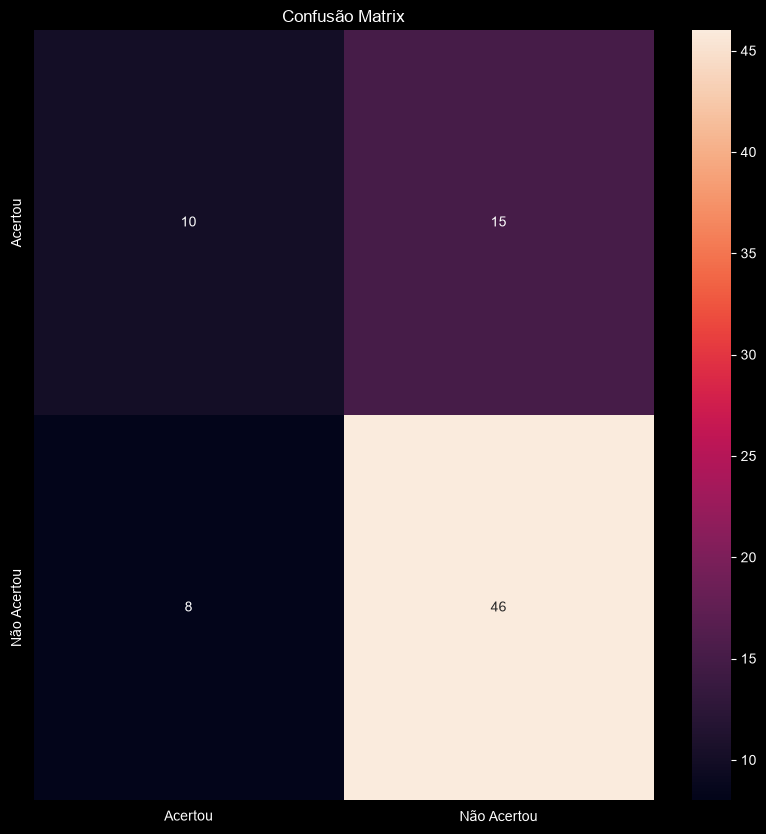

In [41]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(y_test, y_pred, labels=[1, 0])

tabela = pd.DataFrame(
    cm,
    index=['Acertou', 'Não Acertou'],
    columns=['Acertou', 'Não Acertou'],
)
plt.figure(figsize = (10,10))
plt.title('Confusão Matrix')
sns.heatmap(tabela, annot=True)
plt.show()

In [26]:
y_prob = logistic.predict_proba(X_test_scaled)[:,1]

In [27]:
df_resul = X_test.copy()

df_resul['Prob'] = y_prob

df_resul

,Simbolo,Open,High,Low,Close,ret_Close,ret_Open,ret_lag_1,ret_lag_2,ret_lag_3,...,DayOfWeek,open_Tomorrow,high_Tomorrow,low_Tomorrow,close_Tomorrow,open_Prev,high_Prev,low_Prev,close_Prev,Prob
78,2,38.0700,38.2500,37.9300,38.0600,-0.010143,-0.001312,0.004179,-0.026443,0.004085,...,4,38.2000,38.3700,37.9200,38.1400,38.116785,38.504666,37.793073,38.176448,0.518876
275,0,28.6496,29.3998,28.5172,29.3380,0.024028,0.000926,-0.002458,-0.002147,-0.003666,...,0,29.3380,29.5234,29.0997,29.3910,29.309612,29.661902,28.971886,29.293692,0.386054
247,1,7.0095,7.0095,6.6190,6.7048,-0.051212,-0.001353,0.010901,0.019454,0.002779,...,4,6.6095,7.0190,6.6095,6.6857,6.749996,6.942655,6.616015,6.773671,0.076245
55,2,34.7400,35.0100,33.8100,34.5500,-0.040278,-0.039004,-0.032258,-0.002681,0.003767,...,4,33.9200,34.5600,33.1100,33.1800,34.609528,35.017337,34.086378,34.528534,0.136309
388,1,8.7619,9.6000,8.7619,9.0190,0.028228,-0.033618,-0.040633,-0.030301,0.012271,...,3,8.6952,8.7905,8.3810,8.5714,9.031337,9.329752,8.809515,9.079829,0.056411
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
362,3,53.6300,53.8900,51.3800,51.4100,-0.044956,0.025234,0.032611,-0.013250,-0.006581,...,1,51.4100,51.7300,51.0800,51.2400,51.417262,52.060039,50.721938,51.402604,0.324838
82,2,32.3800,32.4100,32.1000,32.2300,-0.001549,0.000927,-0.007990,-0.000921,-0.007617,...,2,32.2800,32.4000,32.2000,32.4000,32.270505,32.527553,32.034571,32.269663,0.547460
114,2,38.7500,39.2100,38.4800,39.1700,0.009536,-0.002831,-0.001287,0.007260,0.000778,...,0,38.9600,39.5700,38.8400,39.3300,39.207542,39.677948,38.773483,39.202525,0.369844
3,2,46.3900,46.5500,45.6700,45.6700,-0.011900,-0.000216,-0.022213,-0.028566,-0.013782,...,4,46.2100,46.5100,45.6500,46.4300,45.729635,46.222628,45.187592,45.731117,0.367610


In [28]:
joblib.dump(
    {
    'modelo': logistic,
    'encoder': encoder,
    'scaler': scaler,
    'features': list(X_train.columns),
},r'C:\Users\relia/OneDrive/Documentos/Projetos/VSCode/Python/Moeda/ML/producao/prob.joblib')

['C:\\Users\\relia/OneDrive/Documentos/Projetos/VSCode/Python/Moeda/ML/producao/prob.joblib']